# Using LLMS 

In [1]:
# General
import os
from pathlib import Path
from tqdm import tqdm

# data manipulation
import json
import pandas as pd
import numpy as np

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt
# from matplotlib import cm
#for theme
%run ../../docs/plotly_theme.ipynb 

# Interactive Jupyter
from IPython.display import display
from tqdm import tqdm

# others
import contractions
from scipy.stats import pearsonr, ttest_ind 
import nltk
nltk.download('stopwords')
import random

# LLMs
import ollama
import base64

os.chdir('../Milestone_P2')
# Custom utility python files
import utils.visualization as viz # custom visualization utils in '/utils/visualization.py'
import utils.visualization2 as viz2 # custom visualization utils in '/utils/visualization2.py'
import utils.data_wrangling as dw # custom data wrangling utils in '/utils/data_wrangling.py'
import utils.structural_analysis as ut # custom structural analysis utils in '/utils/structural_analysis.py'
# import utils.data_augmentation as da # custom data augmentation utils in '/utils/data_augmentations.py'

os.chdir('../Adrian')

PROJECT_ROOT = Path.cwd().parent.parent
FIGURES_DIR = PROJECT_ROOT / 'figures'

# DATA DIRECTORIES
DATA_DIR = PROJECT_ROOT / 'data' / 'newyorker_caption_contest'
JSON_DIR = DATA_DIR / 'contests.json'
CSV_DIR = DATA_DIR / 'data'
CSV_CLEAN_DIR = DATA_DIR / 'cleaned_data'
IMG_DIR = DATA_DIR / 'images'

print("Project path setup:")
print("PROJECT_ROOT:  ", PROJECT_ROOT)
print("FIGURES_DIR:   ", FIGURES_DIR)
print("\nDATA_DIR:      ", DATA_DIR)
print("JSON_DIR:      ", JSON_DIR)
print("CSV_DIR:       ", CSV_DIR)
print("CSV_CLEAN_DIR: ", CSV_CLEAN_DIR)
print("IMG_DIR:       ", IMG_DIR)

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/adrian/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Project path setup:
PROJECT_ROOT:   /Users/adrian/Desktop/Etudes/EPFL/2025-2026/MA1/ADA/ada-2025-project-json-derulo
FIGURES_DIR:    /Users/adrian/Desktop/Etudes/EPFL/2025-2026/MA1/ADA/ada-2025-project-json-derulo/figures

DATA_DIR:       /Users/adrian/Desktop/Etudes/EPFL/2025-2026/MA1/ADA/ada-2025-project-json-derulo/data/newyorker_caption_contest
JSON_DIR:       /Users/adrian/Desktop/Etudes/EPFL/2025-2026/MA1/ADA/ada-2025-project-json-derulo/data/newyorker_caption_contest/contests.json
CSV_DIR:        /Users/adrian/Desktop/Etudes/EPFL/2025-2026/MA1/ADA/ada-2025-project-json-derulo/data/newyorker_caption_contest/data
CSV_CLEAN_DIR:  /Users/adrian/Desktop/Etudes/EPFL/2025-2026/MA1/ADA/ada-2025-project-json-derulo/data/newyorker_caption_contest/cleaned_data
IMG_DIR:        /Users/adrian/Desktop/Etudes/EPFL/2025-2026/MA1/ADA/ada-2025-project-json-derulo/data/newyorker_caption_contest/images


CITE THE DATASET !!!!!
If you use this dataset, we would appreciate you citing our work, but also -- several other papers that we build this corpus upon. See Citation Information.

## Image description

In [ ]:
def _missing_meta(meta, what):
    """
    Check if a single metadata dictionary is missing a given key.
    meta: dictionary that is supposed to contain all the metadata
    what: key that we are looking for
    """
    return (
        not isinstance(meta, dict)
        or what not in meta
        )
    

def ids_missing_key(df, what):
    """
    Returns the contest IDs (not indices) for which the metadata dictionary is missing the key `what`.

    Args:
        metadata_list (list): List of metadata dicts (contests_df['metadata'])
        what (str): Key to check for (e.g. 'num_captions', 'image_descriptions', etc.)
        contest_ids (list or Series): List of contest IDs aligned with metadata_list
    """
    return [
        int(df['contest_id'][i])
        for i, meta in enumerate(df['metadata'])
        if _missing_meta(meta, what)
    ]
    
def _examples_for_ai(df,root,number_of_ex=5):
    examples = []
    for _, complete in random.sample(list(df.iterrows()),number_of_ex):
        image_path=root+'/'+str(complete['contest_id'])+'.jpg'
        with open(image_path, "rb") as f:
                #image = f.read() #test 1
                #image =base64.b64encode(f.read()).decode("utf-8") # test2 
                image=image_path #test3
        meta = complete['metadata']
        
        examples.append({ 
            'image_path': image, 'image_loc': meta.get('image_locations'),
            'image_descri': meta.get('image_descriptions'), 'image_uncan_descri':meta.get('image_uncanny_descriptions'),
            'images_entities': meta.get('entities'),'images_questions': meta.get('questions')
        })
    return examples

def _prompt_making_description(examples):
    prompt = "You are an expert that generates detailed and structured metadata for images.\n\n"
    prompt+=f'Next are some examples for different images, I want your answer to be in the same structure as in the examples\n'    
    for example in examples:  # Fewer examples for smaller models
        prompt += f"Example:\n"
        #prompt += f"image_path: {example['image_path']}\n" # or image_path
        prompt += f"Location: {example['image_loc']}\n"
        prompt += f"Description: {example['image_descri']}\n"
        prompt += f"Uncanny description : {example['image_uncan_descri']}\n"
        prompt += f"Entities: {example['images_entities']}\n"
        prompt += f"Questions: {example['images_questions']}\n\n"
    prompt+='Now to our image !'
    return prompt

def add_image_descriptions(contests_df, root=IMG_DIR): 
    '''
    contests_df: contests dataframe from the Json 
    
    root: Path or str that points the folder where the images are
    
    Returns the metadata, with the id contest, of those who lacked them. 
    ''' 
    root=str(root)
    # Test if Ollama is running and pull a model
    try:
        ollama.list()
    except:
        print("Please install and start Ollama first: https://ollama.ai/")
        return contests_df
    missing_df_ids = ids_missing_key(contests_df,'image_descriptions')
    complete_df = contests_df[~contests_df['contest_id'].isin(missing_df_ids)] ## removes the missings dfs

    required_keys = [
        "image_locations : what location is the image decripting", "image_descriptions : What is happening in the image", "image_uncanny_descriptions : what is special about the image situation",
        "entities: wikipedias links to the entities from the image", "questions: what questions can be asked from the image"," your answer confidence: (between 0-1)"
    ]
    results = []
    for ids in tqdm(missing_df_ids):
        
        meta = contests_df.loc[contests_df['contest_id'] == ids, 'metadata'].iloc[0]
        if not isinstance(meta, dict):
            meta = {}
        image_path=root+'/'+str(ids)+'.jpg'
        examples = _examples_for_ai(complete_df,root,number_of_ex=3)    
        prompt=_prompt_making_description(examples)
        with open(image_path, "rb") as f:
                #image = f.read() test 1
                image =base64.b64encode(f.read()).decode("utf-8") #test 2
                #image=image_path #test3
        #prompt = "You are an expert that generates detailed and structured metadata for images.\n\n"
        prompt += f"""
        Fill in the missing keys: {', '.join(required_keys)}, for the image.
        """
        print(f'id : {ids}, prompt {prompt}')
        try:
            response = ollama.generate(
                model='llava:7b',  # 'llava:7b'
                prompt=prompt,# + image,
                images=[image],
                options={'temperature': 0.1}  # control randomness/creativity, low temp mostly consistent, slight creativity
            )
            description = response['response']
        
            results.append({
            'contest_id': ids,
            'description': description
            })
        except Exception as e:
            print(f"Error processing contest {ids}: {e}")
        break
    return results


In [11]:
file_path = str(JSON_DIR)
with open(file_path, "r") as file:
    contests = json.load(file)
contests_df = pd.DataFrame(contests)
results=add_image_descriptions(contests_df)

  0%|          | 0/144 [00:00<?, ?it/s]

id : 527, prompt You are an expert that generates detailed and structured metadata for images.

Next are some examples for different images, I want your answer to be in the same structure as in the examples
Example:
Location: ['boardroom']
Description: ['Aliens are having a meeting inside a room with a man as a host. The aliens look to be from different homes and planets.']
Uncanny description : ['Aliens are unusual for people on earth.']
Entities: ['https://en.wikipedia.org/wiki/Meeting', 'https://en.wikipedia.org/wiki/Animal']
Questions: ['What are the aliens meeting about?']

Now to our image !
        Fill in the missing keys: image_locations : what location is the image decripting, image_descriptions : What is happening in the image, image_uncanny_descriptions : what is special about the image situation, entities: wikipedias links to the entities from the image, questions: what questions can be asked from the image,  your answer confidence: (between 0-1), for the image.
        


  0%|          | 0/144 [33:01<?, ?it/s]


KeyboardInterrupt: 

In [ ]:
print(results)

## API ?

In [ ]:
import os
from ollama import Client

client = Client(
    host='https://ollama.com',
    headers={'Authorization': 'Bearer ' + os.environ.get('OLLAMA_API_KEY')}
)

messages = [
  {
    'role': 'user',
    'content': 'Why is the sky blue?',
  },
]

for part in client.chat('gpt-oss:120b', messages=messages, stream=True): # models : 'gpt-oss:120b-cloud'
  print(part.message.content, end='', flush=True)

## Joke discription

In [ ]:
def store_joke_classification(classifications):
    for contest_id, captions in classifications.items():
        rows = []
        for cap_id, text in captions.items():
            
            # Extract numbers and labels
            parts = [p.strip() for p in text.split(',')]
            parsed = {}
            
            for part in parts:
                # Example: "0.6 Language"
                num, label = part.strip().split(' ', 1)
                parsed[label] = float(num)
            
            # build row
            row = {
                "caption_id": cap_id,
                **parsed
            }
            rows.append(row)

    
        pd.DataFrame(rows).to_csv('Data_augmented/'+contest_id+'.csv',index=False)
       
        
def _prompt_making_classifictation(cat,description=[],image=False):
    '''
    This function creates the prompt for the catpion calssification.
    It explains 
    '''
    prompt=f"You are an expert in joke classification !\n"
    prompt+=f"Your job is to classify each joke to the following categories : {', '.join(cat)}.\n"
    prompt+=f"I want you to assert the confidence with which you're attributing the category. For example : 0.3 Langauage, 0.6 Logic, 0.0 Identity, 0.1 Action\n"
    prompt+=f"You answer really needs to be in the same structure as in the example !\n"
    prompt+=f"The definitions of the categories are :\n"
    prompt+=f"1) Language; Verbal humor, Allusion, Irony, Puns, Repartee, Wit, Ridicule\n"
    prompt+=f"2) Logic; Ideational humor, Absurdity, Coincidence, Conceptual surprise, Outwitting, Caught out, Misunderstanding\n"
    prompt+=f"3) Identity; Existential humor, Parody, Rigidity, Malicious pleasure, Condescension, Deceitful behavior, Self-deprecation\n"
    prompt+=f"4) Action; Physical/ non-verbal humour, Peculiar face, Peculiar music, Clumsiness, Repulsive behavior\n"
    if description:
        prompt+=f"Use the image description as well as the uncanny image discription to assert the caption category :\n "
        prompt+=f"Description; {description[0]}\n"
        prompt+=f"Uncanny description; {description[1]}\n"
    elif image:
        prompt+=f"Use the image to assert the caption category\n"
    return prompt

def check_done(path,compare=[]):
    done=[]
    for classified in os.listdir(path):
        done.append(classified.split('/')[-1].removesuffix('.csv'))
    if not compare:
        for contest in os.listdir(str(CSV_CLEAN_DIR)):
            compare.append(contest.split('/')[-1].removesuffix('.csv'))
    missing = [c for c in compare if c not in done]
    return missing
    
def classify_captions(cat,image_description=False,image=False,save=False,to_be_done_id=check_done('Data_augmented')):
    '''
    Takes one contest, df, and attribute the captions into one from the given categories, cat.
    It does so using ollama with a specific model. 
    It returns df with a new column with the joke classification
    It takes 5s per caption, if we have 5000 it has to run for 5*5000/3600≈7h per csv, so we decide to classify a sub sampled population,
    0,5% of the top, 0.5% of the worst caption based on The wilson score (lower bound), which is a more robust way of regarding the funniness
    of a catption 
    '''
    file_path = str(JSON_DIR)
    with open(file_path, "r") as file:
        contests = json.load(file)
    contests_df = pd.DataFrame(contests)
    
    contest_class={}
    os.environ['OLLAMA_API_KEY'] = 'ad40aad03c0b4f4b87c61775386ee5ea.eXWcvvEkoBT73umaM7PRW6oA'
    client = ollama.Client(
        host='https://ollama.com',
        headers={'Authorization': 'Bearer ' + os.environ.get('OLLAMA_API_KEY')} # this is my key 
        )
    
    to_be_done_id=check_done('Data_augmented',to_be_done_id)
    print(len(to_be_done_id),' contest left')
    for contest in to_be_done_id:
        df=pd.read_csv(str(CSV_CLEAN_DIR)+'/'+contest+'.csv',engine="python", on_bad_lines="warn")
        length=df.shape[0]
        df1_idx=list(df.iloc[:25,:].index)
        df2_idx=list(df.iloc[(length-25):,:].index)
        index=df1_idx+df2_idx
        descrip=[]
        if image_description:
            contest_json=contests_df[contests_df['contest_id']==contest]
            descrip=[contest_json['metadata'].iloc[0].get('image_descriptions'),contest_json['metadata'].iloc[0].get('image_uncanny_descriptions')]
        prompt=_prompt_making_classifictation(cat,descrip)
        results = {}
        print('======================'+contest+'======================')
        for idx in tqdm(index):
            row=df.iloc[idx,:]
            prompt_cap=prompt + f'Classify this caption : ' + row['caption']
            
            messages = [
                {
                    'role': 'user',
                    'content': prompt_cap,
                },
                ]
            full_response = ''
            # Stream the response and accumulate it
            for part in client.chat('gpt-oss:120b', messages=messages, stream=True): #
                if part.message.content:
                    content = part.message.content
                    full_response += content
                    #print(content, end='', flush=True)
            # Store the complete response
            results[str(idx)] = full_response
        contest_class[str(contest)]=results
        if save:
            store_joke_classification(contest_class)
    return contest_class



In [163]:
#Cat1=['Dark Humour','Irony','Social Commentary','Wordplay','Absurdity'] 
Cat2=['Language','Logic','Identity','Action'] # Berger’s humor categories
#Mariem=['628_cleaned', '819_cleaned', '676_cleaned', '714_cleaned', '799_cleaned', '869_cleaned', '606_cleaned', '894_cleaned', '764_cleaned', '723_cleaned', '597_cleaned', '641_cleaned', '753_cleaned', '631_cleaned', '800_cleaned', '544_cleaned', '692_cleaned', '780_cleaned', '870_cleaned', '534_cleaned', '761_cleaned', '891_cleaned', '528_cleaned', '603_cleaned', '711_cleaned', '558_cleaned', '673_cleaned', '842_cleaned', '832_cleaned', '576_cleaned', '638_cleaned', '857_cleaned', '513_cleaned', '648_cleaned', '827_cleaned', '563_cleaned', '774_cleaned', '884_cleaned', '616_cleaned', '879_cleaned', '789_cleaned', '704_cleaned', '666_cleaned', '809_cleaned', '815_cleaned', '551_cleaned', '718_cleaned', '687_cleaned', '795_cleaned', '865_cleaned', '521_cleaned', '768_cleaned', '736_cleaned', '582_cleaned', '654_cleaned', '746_cleaned', '624_cleaned', '514_cleaned', '850_cleaned', '564_cleaned', '820_cleaned', '599_cleaned']
Marina=['611_cleaned', '773_cleaned', '883_cleaned', '661_cleaned', '703_cleaned', '556_cleaned', '680_cleaned', '812_cleaned', '526_cleaned', '792_cleaned', '862_cleaned', '585_cleaned', '653_cleaned', '731_cleaned', '578_cleaned', '623_cleaned', '741_cleaned', '590_cleaned', '646_cleaned', '829_cleaned', '724_cleaned', '636_cleaned', '859_cleaned', '754_cleaned', '543_cleaned', '695_cleaned', '668_cleaned', '807_cleaned', '533_cleaned', '618_cleaned', '787_cleaned', '877_cleaned', '604_cleaned', '766_cleaned', '674_cleaned', '716_cleaned', '689_cleaned', '748_cleaned', '845_cleaned', '571_cleaned', '738_cleaned', '835_cleaned', '872_cleaned', '782_cleaned', '536_cleaned', '802_cleaned', '546_cleaned', '690_cleaned', '751_cleaned', '518_cleaned', '633_cleaned', '721_cleaned', '568_cleaned', '595_cleaned', '643_cleaned', '830_cleaned', '589_cleaned', '574_cleaned', '840_cleaned', '713_cleaned', '671_cleaned', '893_cleaned']
#Hanna=['763_cleaned', '601_cleaned', '699_cleaned', '706_cleaned', '664_cleaned', '886_cleaned', '776_cleaned', '614_cleaned', '825_cleaned', '561_cleaned', '728_cleaned', '855_cleaned', '511_cleaned', '758_cleaned', '744_cleaned', '849_cleaned', '626_cleaned', '734_cleaned', '580_cleaned', '839_cleaned', '656_cleaned', '867_cleaned', '797_cleaned', '608_cleaned', '523_cleaned', '817_cleaned', '678_cleaned', '553_cleaned', '685_cleaned', '769_cleaned', '520_cleaned', '794_cleaned', '864_cleaned', '686_cleaned', '719_cleaned', '550_cleaned', '814_cleaned', '625_cleaned', '747_cleaned', '655_cleaned', '583_cleaned', '737_cleaned', '562_cleaned', '826_cleaned', '649_cleaned', '512_cleaned', '856_cleaned', '639_cleaned', '808_cleaned', '667_cleaned', '705_cleaned', '878_cleaned', '788_cleaned', '617_cleaned', '775_cleaned', '885_cleaned', '672_cleaned', '559_cleaned', '710_cleaned', '602_cleaned', '529_cleaned', '760_cleaned']
#Jeremy=['890_cleaned', '577_cleaned', '833_cleaned', '843_cleaned', '630_cleaned', '752_cleaned', '640_cleaned', '596_cleaned', '722_cleaned', '535_cleaned', '781_cleaned', '871_cleaned', '693_cleaned', '545_cleaned', '801_cleaned', '629_cleaned', '846_cleaned', '659_cleaned', '836_cleaned', '572_cleaned', '895_cleaned', '765_cleaned', '607_cleaned', '798_cleaned', '868_cleaned', '715_cleaned', '677_cleaned', '818_cleaned', '804_cleaned', '709_cleaned', '696_cleaned', '874_cleaned', '784_cleaned', '779_cleaned', '889_cleaned', '530_cleaned', '727_cleaned', '645_cleaned', '593_cleaned', '757_cleaned', '635_cleaned', '732_cleaned', '650_cleaned', '586_cleaned', '742_cleaned', '620_cleaned', '811_cleaned', '683_cleaned', '555_cleaned', '861_cleaned', '791_cleaned', '539_cleaned', '880_cleaned', '770_cleaned', '612_cleaned', '549_cleaned', '700_cleaned', '662_cleaned', '853_cleaned', '517_cleaned', '823_cleaned', '567_cleaned']
results = classify_captions(Cat2,save=True,to_be_done_id=Marina) ## Mettre vontre prenom ici


41  contest left
======================636_cleaned======================


100%|██████████| 50/50 [01:31<00:00,  1.83s/it]


======================859_cleaned======================


 76%|███████▌  | 38/50 [01:16<00:24,  2.00s/it]


ResponseError: you've reached your weekly usage limit, please wait or upgrade to continue (status code: 429)

In [169]:
def correct_format_LLMS(input_dir):
    for csv_file in os.listdir(input_dir):
        if not csv_file.endswith("cleaned.csv"):
            continue

        path = os.path.join(input_dir, csv_file)
        df = pd.read_csv(path)


        # ---- 1. Keep only the last 50 rows ----
        df = df.iloc[-50:].copy()
        df = df.loc[:, ~df.columns.str.contains("^Unnamed")]
        # ---- 2. Rename columns properly ----
        if not df.shape[1]==5: # Correct number of columns
            df.columns = [
                "caption_id",
                "Language_1",
                "Logic",
                "Identity",
                "Action",
                "Language_2"]

            # ---- 3. Merge duplicated Language columns ----
            df["Language"] = df["Language_1"].combine_first(df["Language_2"])

            # ---- 4. Drop old duplicated columns ----
            df = df.drop(columns=["Language_1", "Language_2"])

        # ---- 5. Ensure numeric columns are numeric ----
        for col in ["Language", "Logic", "Identity", "Action"]:
            df[col] = pd.to_numeric(df[col], errors="coerce")
            
       
        df = df.loc[:, ~df.columns.str.contains("^Unnamed")]
        df.to_csv(input_dir+'/'+csv_file,index=False)
    
input_dir = "Data_augmented"
correct_format_LLMS(input_dir)




In [171]:
def add_observables_LLMS(input_dir):
    all_dfs = []
    for csv_file in os.listdir(input_dir):
        if not csv_file.endswith('.csv'):
            continue
        
        path = os.path.join(input_dir, csv_file)
        df = pd.read_csv(path)
        
        clean_path = os.path.join(str(CSV_CLEAN_DIR), csv_file)
        real_df = pd.read_csv(clean_path)
        
        df['mean'] = real_df.iloc[df['caption_id'].values]['mean'].values
        
        contest_id = csv_file.replace('_cleaned.csv', '').replace('.csv', '')
        df['contest_id'] = contest_id
        
        df['dominant_category'] = df[['Logic', 'Identity', 'Action', 'Language']].idxmax(axis=1)

        # Identify the value of the dominant category
        df['dominant_value'] = df[['Logic', 'Identity', 'Action', 'Language']].max(axis=1)
        df_filtered = df[df['dominant_value'] > 0.25].dropna()  # errors in chatgpt

        all_dfs.append(df_filtered)
        
    super_df = pd.concat(all_dfs, ignore_index=True)
    super_df.to_csv('Data_augmented/super.csv', index=False)
    return super_df
        
input_dir = "Data_augmented"   
df=add_observables_LLMS(input_dir)
        

In [2]:

# Keep only the columns you need
df=pd.read_csv('Data_augmented/super.csv')
result_df = df[['caption_id', 'dominant_category', 'dominant_value', 'mean', 'contest_id']].copy()
df.sort_values('dominant_value') 


,caption_id,Logic,Identity,Action,Language,mean,contest_id,dominant_category,dominant_value
2340,4862.0,0.30,0.30,0.10,0.30,1.000000,632,Logic,0.30
9018,20.0,0.30,0.20,0.20,0.30,1.726974,551,Logic,0.30
8044,3921.0,0.30,0.10,0.00,0.20,1.000000,558,Logic,0.30
1641,5179.0,0.30,0.00,0.00,0.20,1.040541,892,Logic,0.30
3450,2.0,0.30,0.20,0.25,0.25,1.589912,532,Logic,0.30
...,...,...,...,...,...,...,...,...,...
5528,9069.0,0.03,0.02,0.01,0.94,1.086420,651,Language,0.94
1908,8.0,0.95,0.00,0.05,0.00,1.821703,803,Logic,0.95
5020,22.0,0.95,0.03,0.02,0.00,1.616131,881,Logic,0.95
9966,18.0,0.95,0.00,0.05,0.00,1.673720,883,Logic,0.95


In [172]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px


def plot_df_pairgrid_plotly_simple(
    df: pd.DataFrame,
    cols: list,
    color_by: str = None,
    title: str = "Pair Grid Plot",
    color_continuous_scale=None, 
    **kwargs
):
    numeric_cols = [c for c in cols if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
    if not numeric_cols:
        raise ValueError("No numeric columns found.")

    fig = px.scatter_matrix(
        df,
        dimensions=numeric_cols,
        color=color_by,
        title=title,
        **kwargs
    )

    fig.update_traces(marker=dict(size=4,color="#27AE60"))

    fig.update_layout(
        plot_bgcolor="white",
        paper_bgcolor="white",
        width=740,
        height=600
    )
    fig.write_html("../Pair_wise_caption_classification.html")
    return fig

def plot_histograms_subplot(
    df: pd.DataFrame,
    cols: list,
    nbins: int = 30,
    title: str = "Histograms"
):
    numeric_cols = [c for c in cols if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
    n = len(numeric_cols)

    fig = make_subplots(
        rows=1,
        cols=n,
        subplot_titles=numeric_cols
    )

    for i, col in enumerate(numeric_cols, start=1):
        fig.add_trace(
            go.Histogram(
                x=df[col],
                nbinsx=nbins,
                name=col,
                showlegend=False
            ),
            row=1,
            col=i
        )

    fig.update_layout(
        title=title,
        bargap=0.05,
        plot_bgcolor="white",
        paper_bgcolor="white",
        width=740,
        height=600
    )
    fig.write_html("../Histogram_caption_classification.html")
    return fig

def plot_dominant_vs_mean(
    df,
    categories=("Logic", "Identity", "Action", "Language"),
    title="Dominant category strength vs mean funniness"
):
    fig = make_subplots(
        rows=1,
        cols=4,
        subplot_titles=categories,
        shared_yaxes=True
    )

    positions = {
        "Logic": (1, 1),
        "Identity": (1, 2),
        "Action": (1, 3),
        "Language": (1, 4),
    }

    for cat in categories:
        r, c = positions[cat]

        sub = df[df["dominant_category"] == cat]

        fig.add_trace(
            go.Scatter(
                x=sub["dominant_value"],
                y=sub["mean"],
                mode="markers",
                marker=dict(size=5, opacity=0.5),
                name=cat,
                showlegend=False
            ),
            row=r,
            col=c
        )

        fig.update_xaxes(title_text="Dominant value", row=r, col=c)

    fig.update_yaxes(title_text="Mean funniness", row=1, col=1)

    fig.update_layout(
        title=title,
        plot_bgcolor="white",
        paper_bgcolor="white",
        width=740,
        height=600
    )
    fig.write_html("../Dominant_caption_classification_vs_mean.html")
    return fig


cols = ['Logic', 'Identity', 'Action', 'Language', 'mean']

fig_pair = plot_df_pairgrid_plotly_simple(df,cols=cols,title='Pairwise relationships')
fig_hist = plot_histograms_subplot(df,cols=cols,title='Marginal distributions')
fig_comp=plot_dominant_vs_mean(df,title='Dominant Cat vs Mean')

fig_pair.show()
fig_hist.show()
fig_comp.show()

<Figure size 640x480 with 0 Axes>

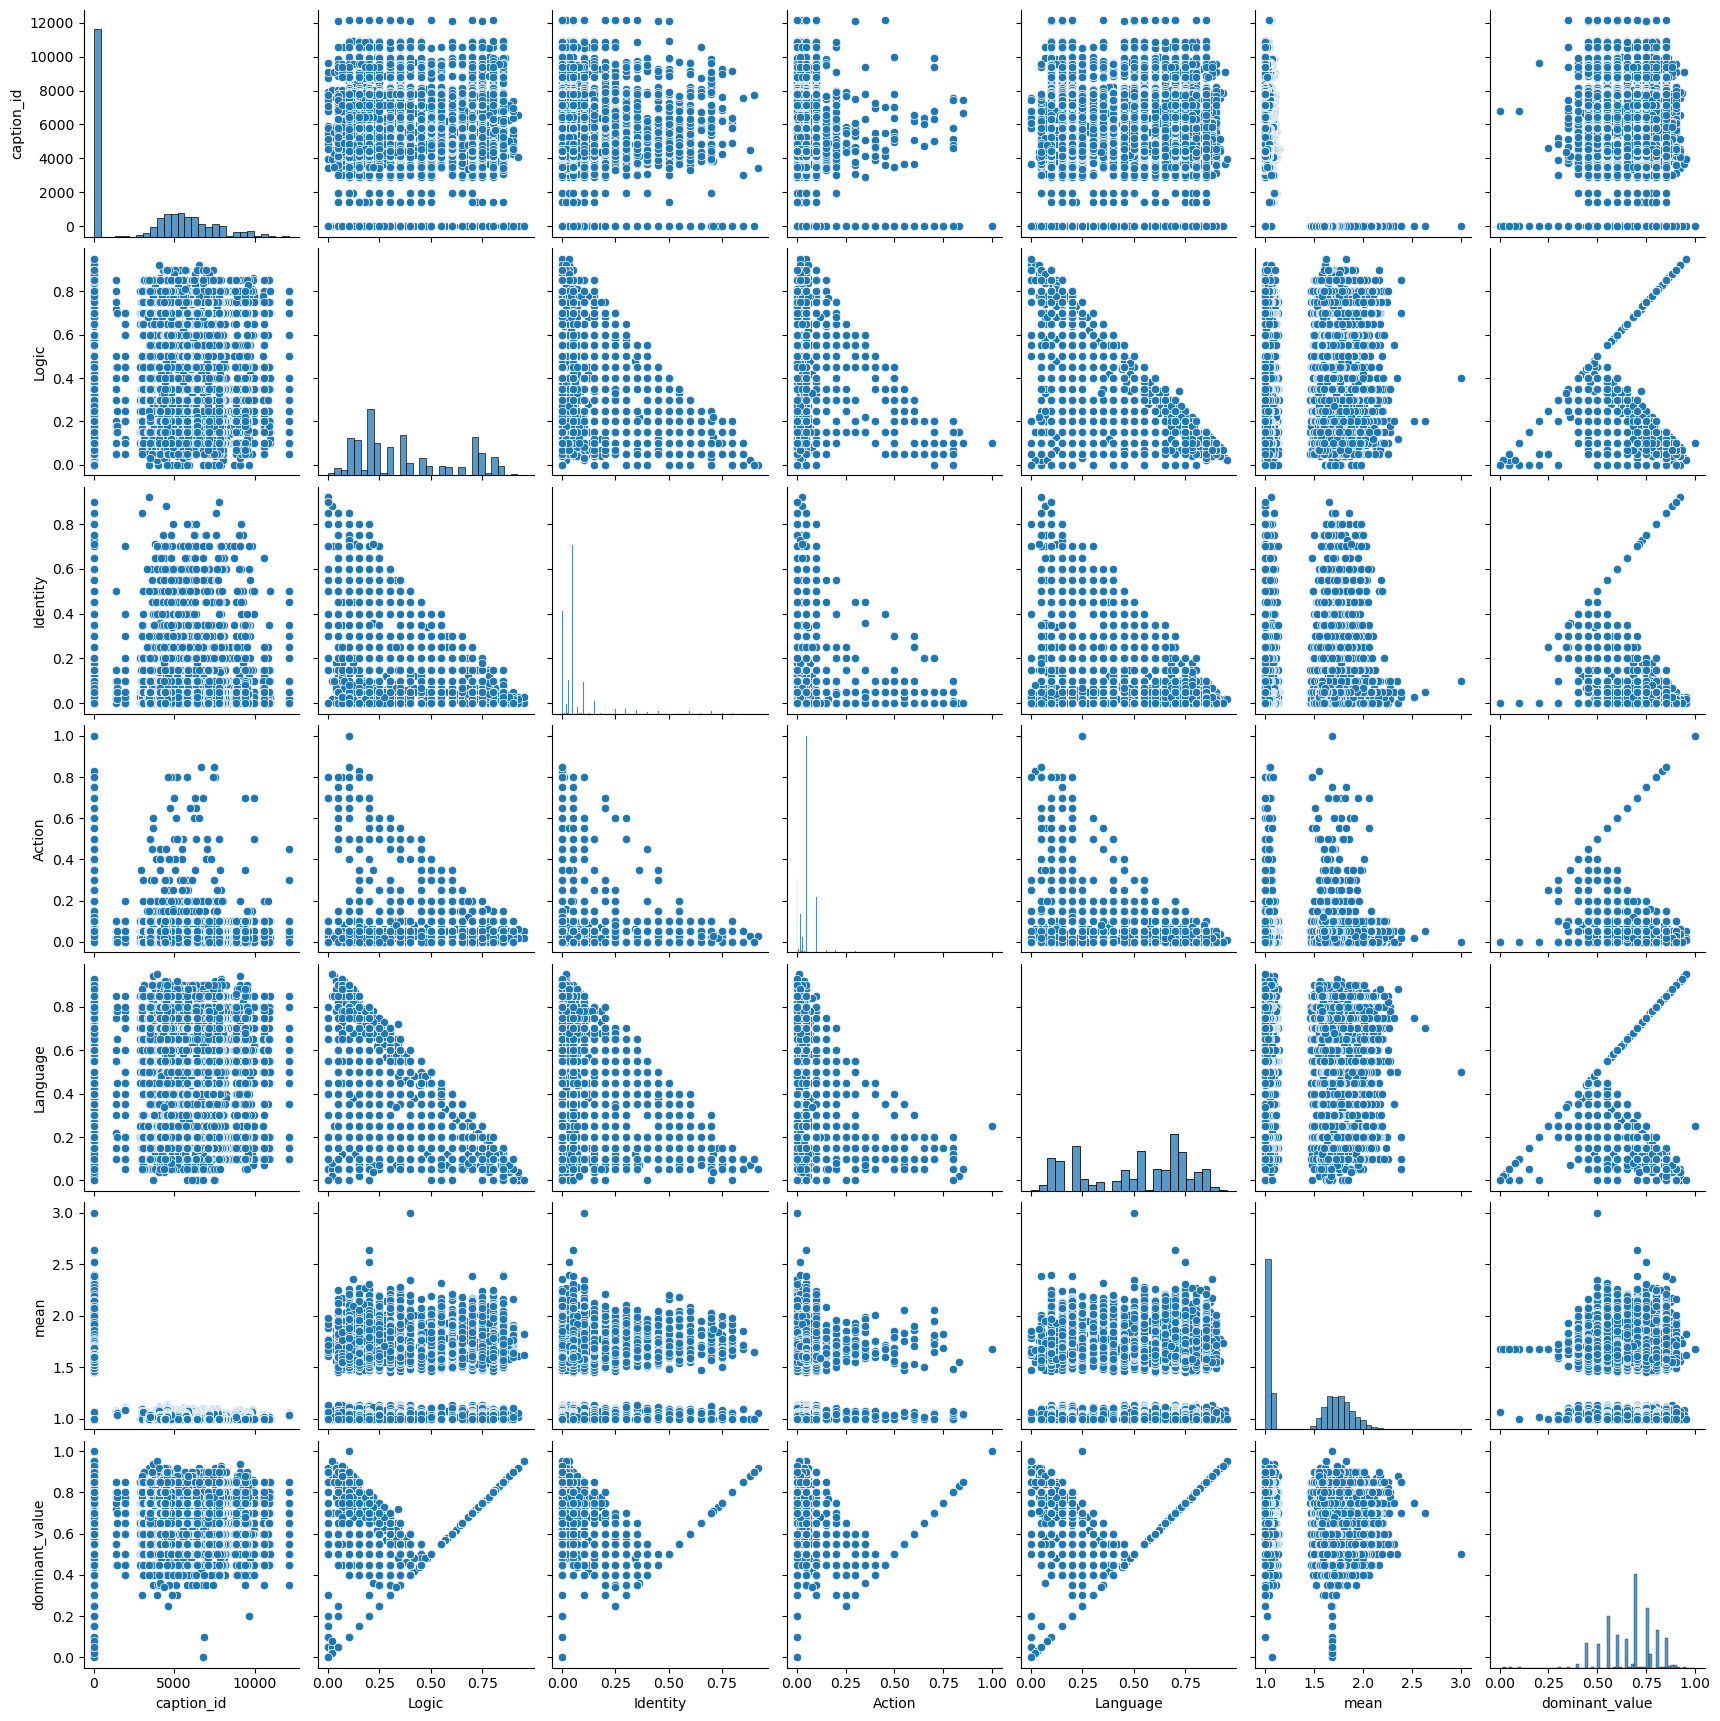

In [129]:
plt.figure()
sns.pairplot(df)
plt.show()

#import plotly.express as px
#fig = px.scatter_matrix(df)
#fig.show()


In [167]:
stats = df[['Logic','Identity','Action','Language','mean']].describe()
stats

,Logic,Identity,Action,Language,mean
count,16496.000000,16496.00000,16496.000000,16496.000000,16496.000000
mean,0.378270,0.07409,0.049553,0.497930,1.392856
std,0.238943,0.11804,0.054511,0.253709,0.379334
min,0.000000,0.00000,0.000000,0.000000,1.000000
25%,0.200000,0.02000,0.020000,0.200000,1.021277
50%,0.300000,0.05000,0.050000,0.550000,1.166667
75%,0.600000,0.05000,0.050000,0.700000,1.747688
max,0.950000,0.92000,0.850000,0.950000,2.998918


In [173]:
# Assuming df is your DataFrame
# Identify dominant category for each row


def descriptive_analysis(df):
    df_copy=df.copy()
    # Compute statistics by dominant category
    stats = df_copy.groupby('dominant_category')['mean'].agg(['mean', 'std','sem','count']).reset_index() 

    # Add additional statistics
    stats['sem'] = stats['std'] / np.sqrt(stats['count'])  # Standard error
    stats['ci_lower'] = stats['mean'] - 1.96 * stats['sem']  # 95% CI lower
    stats['ci_upper'] = stats['mean'] + 1.96 * stats['sem']  # 95% CI upper

    print('Statistics by dominant category:')
    print(stats)
    
    fig = px.bar(stats,
        x='dominant_category',
        y='mean',
        error_y='sem',
        text='count',
        title="Mean funniness by dominant category (± SEM)",
    )
    
    
    fig.update_layout(
        plot_bgcolor='white',
        paper_bgcolor='white',
        yaxis_title="Mean funniness",
        xaxis_title="Dominant category",
        width=740,
        height=600
        
    )
    fig.write_html("Mean_bar_plot_caption_classification.html")
    fig.show()
    
    return stats    

stats=descriptive_analysis(df)

Statistics by dominant category:
  dominant_category      mean       std       sem  count  ci_lower  ci_upper
0            Action  1.384522  0.372501  0.037438     99  1.311144  1.457900
1          Identity  1.405824  0.375979  0.014071    714  1.378245  1.433402
2          Language  1.388062  0.379287  0.003518  11623  1.381167  1.394958
3             Logic  1.398532  0.378746  0.004624   6709  1.389469  1.407595


In [148]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

df_copy=df.copy()
df_copy["mean_minus_1"] = df_copy["mean"] - 1
#X = df[["Logic", "Identity", "Action", "Language"]]
#y = df["mean"]

#X = sm.add_constant(X)
#model = sm.OLS(y, X).fit()
#mod= smf.ols(formula='mean_minus_1 ~ Logic + Identity + Action + Language ',data=df_copy)
mod= smf.ols(formula='mean~ Logic + Identity + Action + Language',data=df_copy)
res = mod.fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:                   mean   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     5.571
Date:                Thu, 18 Dec 2025   Prob (F-statistic):           0.000177
Time:                        19:22:44   Log-Likelihood:                -7253.6
No. Observations:               16095   AIC:                         1.452e+04
Df Residuals:                   16090   BIC:                         1.456e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.9075      0.499      1.820      0.0

Correlation Matrix:
             Logic  Identity    Action  Language      mean
Logic     1.000000 -0.203146  0.079142 -0.854863  0.015553
Identity -0.203146  1.000000  0.005674 -0.289862  0.004557
Action    0.079142  0.005674  1.000000 -0.283616 -0.028162
Language -0.854863 -0.289862 -0.283616  1.000000 -0.010047
mean      0.015553  0.004557 -0.028162 -0.010047  1.000000


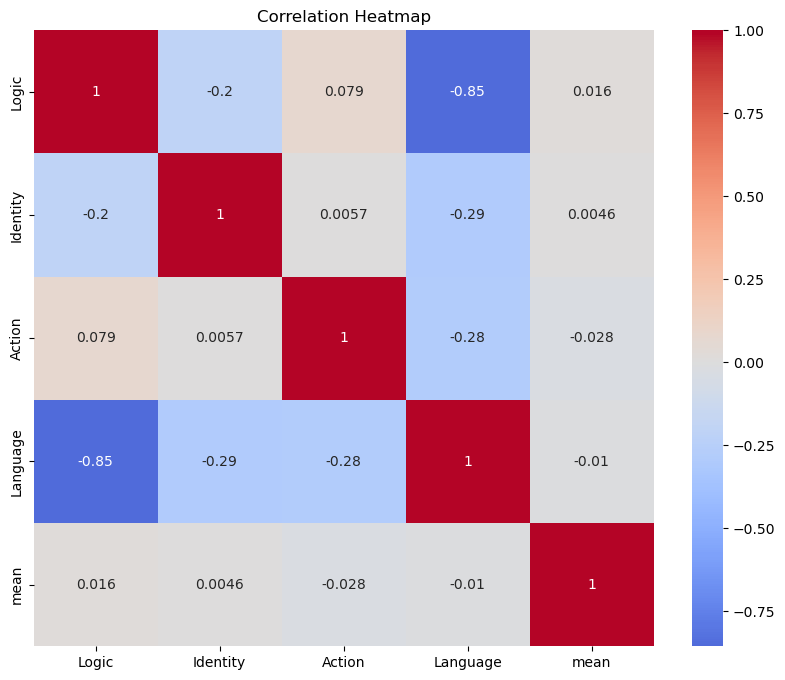

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

# Correlation matrix

def heatmap(df,cols):
    corr_matrix = df[cols].corr()
    print("Correlation Matrix:")
    print(corr_matrix)
    # Heatmap
    fig = px.imshow(corr_matrix,text_auto='.2f', zmin=-1, zmax=1,labels=dict(color="Correlation"),title='Correlation Heatmap')
    fig.update_layout(width=740, height=600)
    fig.show()
    
heatmap(df_copy,['Logic', 'Identity', 'Action', 'Language', 'mean'])

In [174]:
# Calculate correlation matrix (same as before)
corr_matrix = df_copy[['Logic', 'Identity', 'Action', 'Language', 'mean']].corr()
print("Correlation Matrix:")
print(corr_matrix)

# Create interactive heatmap
fig = px.imshow(corr_matrix,
                text_auto='.2f', 
                zmin=-1, 
                zmax=1,  
                labels=dict(color="Correlation"),
                title='Correlation Heatmap')



# Adjust figure size (Plotly uses pixels)
fig.update_layout(width=740, height=600)
fig.write_html("Corrolation_caption_classification.html")
fig.show()

Correlation Matrix:
             Logic  Identity    Action  Language      mean
Logic     1.000000 -0.201322  0.079649 -0.866303  0.019185
Identity -0.201322  1.000000 -0.013354 -0.267251  0.001310
Action    0.079649 -0.013354  1.000000 -0.283230 -0.028844
Language -0.866303 -0.267251 -0.283230  1.000000 -0.012308
mean      0.019185  0.001310 -0.028844 -0.012308  1.000000


In [52]:
from statsmodels.formula.api import rlm

# Robust regression to handle outliers
mod_robust = rlm(formula='mean_minus_1 ~ Logic + Identity + Action + Language', data=df_copy)
res_robust = mod_robust.fit()
print(res_robust.summary())

                    Robust linear Model Regression Results                    
Dep. Variable:           mean_minus_1   No. Observations:                 6800
Model:                            RLM   Df Residuals:                     6795
Method:                          IRLS   Df Model:                            4
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Thu, 18 Dec 2025                                         
Time:                        14:47:37                                         
No. Iterations:                     9                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.1136      0.360     -0.315      0.7

## Wilson metric

In [ ]:
# Caption only


import pandas as pd
import numpy as np

def wilson_metric_95(p, n):
    '''
    p, frequence --> probability : N(sucess)/N(tot)
    N, number of trial 
    
    '''
    den=1/(1+1.96/n) #1.96 ~~> Z value for 95% confidence interval
    nume=p+(1.96**2)/(2*n)
    term=1.96*np.sqrt((p*(1-p)/n) +(1.96**2/(4*n**2)))
    return ((nume-term)/den,(nume+term)/den)
    
    
def add_wilson_metrics(df):
    """
    Add Wilson score (lower bond) to DataFrame. Conservative estimate of the funniness probability.
    """
    df = df.copy()
    
    wilson_scores = []
    wilson_negative_scores = []
    wilson_funny_scores = []
    
    for idx, row in df.iterrows():
        total_votes = row['votes']
        
        if total_votes == 0:
            wilson_scores.append(0)
            wilson_negative_scores.append(0)
            wilson_funny_scores.append(0)
            continue
        
        p_funny=row['funny']/total_votes
        p_negative=row['not_funny']/total_votes
        
        ci_funny = wilson_metric_95(p_funny, total_votes)
        wilson_funny_scores.append(ci_funny[0])
        
        ci_negative = wilson_metric_95(p_negative, total_votes)
        wilson_negative_scores.append(ci_negative[0])
        
        wilson_combined = 0.5 * ci_funny[0] + 0.5 * ci_negative[0]
        wilson_scores.append(wilson_combined)
    
    df['wilson_score_funny'] = wilson_funny_scores
    df['wilson_score_negative'] = wilson_negative_scores
    df['wilson_score'] = wilson_scores
    return df


    